Config

In [8]:
import json, re, os, random
import numpy as np, pandas as pd
 
DATASET_PATH = "../data/tanglish.jsonl"
TRIPLES_PATH = "../data/parallel_triples.csv"
RESULTS_DIR  = "../results"
os.makedirs(RESULTS_DIR, exist_ok=True)
 
TOKENIZERS = {                      # tokenizers only, no model weights are downloaded
    "gemma-2b":      "google/gemma-2b",        # the model you fine-tuned
    "qwen2.5-0.5b":  "Qwen/Qwen2.5-0.5B",      # recent multilingual-ish small LM
    "xlm-roberta":   "xlm-roberta-base",       # multilingual, trained on Tamil
    "mt5":           "google/mt5-small",       # multilingual, trained on Tamil
    "gpt2":          "gpt2",                   # English-centric reference point
}
 
with open(DATASET_PATH, "r", encoding="utf-8") as f:
    raw = [json.loads(l) for l in f]
outs = [r["output"].strip() for r in raw if r.get("output", "").strip()]
ins  = [r["instruction"].strip() for r in raw if r.get("instruction", "").strip()]
print(f"{len(outs)} Tanglish outputs | {len(ins)} English instructions")


613 Tanglish outputs | 613 English instructions


Load Tokenizers

In [9]:
from transformers import AutoTokenizer
 
toks = {}
for name, hub in TOKENIZERS.items():
    try:
        toks[name] = AutoTokenizer.from_pretrained(hub)
    except Exception as e:
        print("SKIPPED", name, "->", str(e)[:150])
print("Loaded:", {k: len(t) for k, t in toks.items()}, "(name: vocab size)")
 


[transformers] Could not extract SentencePiece model from /home/prathoseraajv/.cache/huggingface/hub/models--google--mt5-small/snapshots/73fb5dbe4756edadc8fbe8c769b0a109493acf7a/spiece.model using sentencepiece library due to 
SentencePieceExtractor requires the protobuf library but it was not found in your environment. Check out the instructions on the
installation page of its repo: https://github.com/protocolbuffers/protobuf/tree/master/python#installation and follow the ones
that match your environment. Please note that you may need to restart your runtime after installation.
. Falling back to TikToken extractor.


SKIPPED mt5 -> `tiktoken` is required to read a `tiktoken` file. Install it with `pip install tiktoken`.
Loaded: {'gemma-2b': 256000, 'qwen2.5-0.5b': 151665, 'xlm-roberta': 250002, 'gpt2': 50257} (name: vocab size)


Helper

In [10]:
def strip_ticks(t):
    return t.replace("`", "")
 
def split_ticks(text):
    """Return (backticked terms joined by spaces, the rest of the sentence)."""
    spans = re.findall(r"`([^`]+)`", text)
    rest = re.sub(r"`[^`]+`-?[A-Za-z]*", " ", text)
    return " ".join(spans), rest
 
def ntoks(tok, texts):
    enc = tok(list(texts), add_special_tokens=False)
    return np.array([len(x) for x in enc["input_ids"]], dtype=float)
 
def nwords(texts):
    return np.array([len(t.split()) for t in texts], dtype=float)
 
def nchars(texts):
    return np.array([len(t) for t in texts], dtype=float)
 
def boot_ratio(num, den, B=5000, seed=0):
    """Ratio of sums (corpus-level) with a bootstrap 95% CI over texts."""
    rng = np.random.default_rng(seed)
    n = len(num)
    idx = rng.integers(0, n, (B, n))
    denom = den[idx].sum(1)
    r = num[idx].sum(1) / np.where(denom == 0, np.nan, denom)
    return num.sum() / den.sum(), np.nanpercentile(r, 2.5), np.nanpercentile(r, 97.5)


Fertility of Tanglish DataSet

In [11]:
ins_clean = [strip_ticks(i) for i in ins]
tgl_all   = [strip_ticks(o) for o in outs]
pairs     = [split_ticks(o) for o in outs]
tgl_terms = [p[0] for p in pairs]        # backticked English technical terms
tgl_rest  = [p[1] for p in pairs]        # Tamil glue words + anything not in backticks
 
rowsA = []
def add_rows(tname, tok, label, texts):
    n, w, c = ntoks(tok, texts), nwords(texts), nchars(texts)
    f, lo, hi = boot_ratio(n, w)
    rowsA.append({"tokenizer": tname, "text_type": label, "fertility": f, "ci_low": lo, "ci_high": hi,
                  "chars_per_token": c.sum() / n.sum(), "total_words": int(w.sum()), "n_texts": len(texts)})
 
for tname, tok in toks.items():
    add_rows(tname, tok, "English instructions (not parallel)", ins_clean)
    add_rows(tname, tok, "Tanglish outputs: all words", tgl_all)
    add_rows(tname, tok, "Tanglish outputs: non-backtick words", tgl_rest)
    add_rows(tname, tok, "Tanglish outputs: backticked terms", tgl_terms)
 
dfA = pd.DataFrame(rowsA)
dfA.to_csv(f"{RESULTS_DIR}/fertility_partA.csv", index=False)
print(dfA.round(3).to_string(index=False))


   tokenizer                            text_type  fertility  ci_low  ci_high  chars_per_token  total_words  n_texts
    gemma-2b  English instructions (not parallel)      1.251   1.235    1.267            4.583         5172      613
    gemma-2b          Tanglish outputs: all words      2.143   2.130    2.157            3.526        39666      613
    gemma-2b Tanglish outputs: non-backtick words      2.251   2.238    2.265            3.395        33275      613
    gemma-2b   Tanglish outputs: backticked terms      1.802   1.752    1.854            3.780         7960      613
qwen2.5-0.5b  English instructions (not parallel)      1.252   1.237    1.267            4.580         5172      613
qwen2.5-0.5b          Tanglish outputs: all words      2.169   2.157    2.181            3.484        39666      613
qwen2.5-0.5b Tanglish outputs: non-backtick words      2.316   2.302    2.330            3.300        33275      613
qwen2.5-0.5b   Tanglish outputs: backticked terms      1.720   1

Visualization

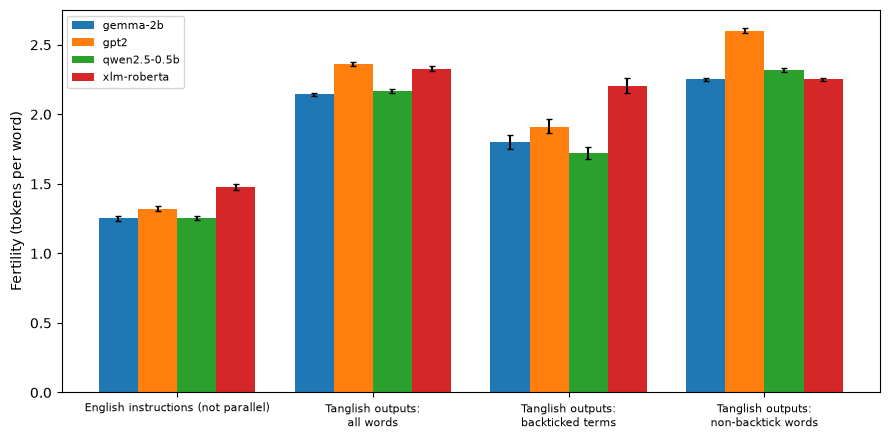

In [12]:
import matplotlib.pyplot as plt
 
piv = dfA.pivot(index="text_type", columns="tokenizer", values="fertility")
err_lo = dfA.pivot(index="text_type", columns="tokenizer", values="ci_low")
err_hi = dfA.pivot(index="text_type", columns="tokenizer", values="ci_high")
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.8 / len(piv.columns)
for j, col in enumerate(piv.columns):
    x = np.arange(len(piv.index)) + j * width
    ax.bar(x, piv[col].values, width, label=col,
           yerr=[piv[col].values - err_lo[col].values, err_hi[col].values - piv[col].values], capsize=2)
ax.set_xticks(np.arange(len(piv.index)) + width * (len(piv.columns) - 1) / 2)
ax.set_xticklabels([t.replace(": ", ":\n") for t in piv.index], fontsize=8)
ax.set_ylabel("Fertility (tokens per word)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/fig_fertility_partA.png", dpi=200)
piv.round(2).to_latex(f"{RESULTS_DIR}/tab_fertility_partA.tex", caption="Sub-token fertility (tokens/word).",
                      label="tab:fertility")
plt.show()


BUild a Parllel-triples template

In [13]:
MARKERS = set("""pannum panni pannalaam pannanum pannuvom pannuradhu panna aagum aagura irukku irukkum
irukkura illa illana vechi vachi dhaan oru ovvoru adhu idhu mattum aana appuram mudhalla romba ungal
varum pogum thevai kedaikkum maadhiri adhunaala kammi nalla theriyum kandupidikkum""".split())
 
def sentences(text):
    return [p.strip() for p in re.split(r"(?<=[.!?])\s+", text) if p.strip()]
 
cands = []
for o in outs:
    for s in sentences(o):
        n_words = len(strip_ticks(s).split())
        if 8 <= n_words <= 30 and not re.search(r"[=<>{}\[\]\\|]|->", s):
            hits = sum(w in MARKERS for w in re.findall(r"[a-z]+", s.lower()))
            if hits >= 2:
                cands.append(strip_ticks(s))
cands = sorted(set(cands))
random.Random(0).shuffle(cands)
pick = cands[:100]
print(f"{len(cands)} candidate sentences, picked {len(pick)}")
 
if os.path.exists(TRIPLES_PATH):
    print("Triples file already exists, not overwriting:", TRIPLES_PATH)
else:
    pd.DataFrame({"id": range(len(pick)), "tanglish": pick, "english": "", "tamil": ""}).to_csv(
        TRIPLES_PATH, index=False, encoding="utf-8-sig")
    print("Template written. Fill the 'english' and 'tamil' columns, then run Part B.")


1579 candidate sentences, picked 100
Triples file already exists, not overwriting: ../data/parallel_triples.csv


Comparison

In [14]:

tri = pd.read_csv(TRIPLES_PATH, encoding="utf-8-sig")
tri = tri.dropna(subset=["english", "tamil", "tanglish"]).reset_index(drop=True)
print(f"{len(tri)} complete triples")
 
if len(tri) >= 20:
    cols = {"English": "english", "Tamil script": "tamil", "Tanglish": "tanglish"}
    N = len(tri)
    rng = np.random.default_rng(1)
    idx = rng.integers(0, N, (5000, N))               # shared resamples -> paired comparisons
    fert_rows, prem_rows = [], []
    for tname, tok in toks.items():
        n = {k: ntoks(tok, tri[c].tolist()) for k, c in cols.items()}
        w = {k: nwords(tri[c].tolist()) for k, c in cols.items()}
        ch = {k: nchars(tri[c].tolist()) for k, c in cols.items()}
        for k in cols:
            r = n[k][idx].sum(1) / w[k][idx].sum(1)
            fert_rows.append({"tokenizer": tname, "language": k, "fertility": n[k].sum() / w[k].sum(),
                              "ci_low": np.percentile(r, 2.5), "ci_high": np.percentile(r, 97.5),
                              "chars_per_token": ch[k].sum() / n[k].sum()})
        # Token premium: total tokens needed for the SAME content, relative to English.
        # (More reliable than fertility across languages: Tamil words are long/agglutinative.)
        for a, b in [("Tamil script", "English"), ("Tanglish", "English"), ("Tanglish", "Tamil script")]:
            r = n[a][idx].sum(1) / n[b][idx].sum(1)
            prem_rows.append({"tokenizer": tname, "comparison": f"{a} / {b}", "token_ratio": n[a].sum() / n[b].sum(),
                              "ci_low": np.percentile(r, 2.5), "ci_high": np.percentile(r, 97.5)})
    fert = pd.DataFrame(fert_rows); prem = pd.DataFrame(prem_rows)
    fert.to_csv(f"{RESULTS_DIR}/fertility_partB_parallel.csv", index=False)
    prem.to_csv(f"{RESULTS_DIR}/token_premium_partB.csv", index=False)
    print(fert.round(3).to_string(index=False))
    print()
    print(prem.round(3).to_string(index=False))
    fert.pivot(index="language", columns="tokenizer", values="fertility").round(2).to_latex(
        f"{RESULTS_DIR}/tab_fertility_partB.tex", caption="Fertility on parallel sentences.", label="tab:fert_parallel")
    prem.pivot(index="comparison", columns="tokenizer", values="token_ratio").round(2).to_latex(
        f"{RESULTS_DIR}/tab_token_premium.tex", caption="Token ratio for identical content.", label="tab:premium")
else:
    print("Fill at least 20 (ideally 100) complete rows in", TRIPLES_PATH, "to run Part B.")


0 complete triples
Fill at least 20 (ideally 100) complete rows in ../data/parallel_triples.csv to run Part B.
